In [5]:
from pydub import AudioSegment
import glob
import os

# Tìm tất cả file m4a trong cấu trúc thư mục dataset
m4a_files = glob.glob("dataset/*/*.m4a")

for file in m4a_files:
    try:
        # Đọc file m4a đầu vào
        audio = AudioSegment.from_file(file, format="m4a")
        
        # Thiết lập đúng chuẩn: Mono (1 kênh) và tần số lấy mẫu 16kHz[cite: 3, 10]
        audio = audio.set_channels(1)
        audio = audio.set_frame_rate(16000)
        
        # Thay đuôi .m4a thành .wav cho file đích
        wav_filename = file.replace(".m4a", ".wav")
        
        # Xuất ra file chuẩn wav
        audio.export(wav_filename, format="wav")
        print(f"Đã tạo: {wav_filename}")
        
        # Xóa file .m4a cũ sau khi đã tạo thành công file .wav
        os.remove(file)
        print(f"Đã xóa file gốc: {file}")
        print("-" * 30)
        
    except Exception as e:
        print(f"Có lỗi xảy ra với file {file}: {e}")

print("Hoàn tất quá trình chuyển đổi và dọn dẹp!")

Đã tạo: dataset\ba\ba_01.wav
Đã xóa file gốc: dataset\ba\ba_01.m4a
------------------------------
Đã tạo: dataset\ba\ba_02.wav
Đã xóa file gốc: dataset\ba\ba_02.m4a
------------------------------
Đã tạo: dataset\ba\ba_03.wav
Đã xóa file gốc: dataset\ba\ba_03.m4a
------------------------------
Đã tạo: dataset\ba\ba_04.wav
Đã xóa file gốc: dataset\ba\ba_04.m4a
------------------------------
Đã tạo: dataset\ba\ba_05.wav
Đã xóa file gốc: dataset\ba\ba_05.m4a
------------------------------
Đã tạo: dataset\bon\bon_01.wav
Đã xóa file gốc: dataset\bon\bon_01.m4a
------------------------------
Đã tạo: dataset\bon\bon_02.wav
Đã xóa file gốc: dataset\bon\bon_02.m4a
------------------------------
Đã tạo: dataset\bon\bon_03.wav
Đã xóa file gốc: dataset\bon\bon_03.m4a
------------------------------
Đã tạo: dataset\bon\bon_04.wav
Đã xóa file gốc: dataset\bon\bon_04.m4a
------------------------------
Đã tạo: dataset\bon\bon_05.wav
Đã xóa file gốc: dataset\bon\bon_05.m4a
------------------------------


c:\Users\DINHDUNG\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


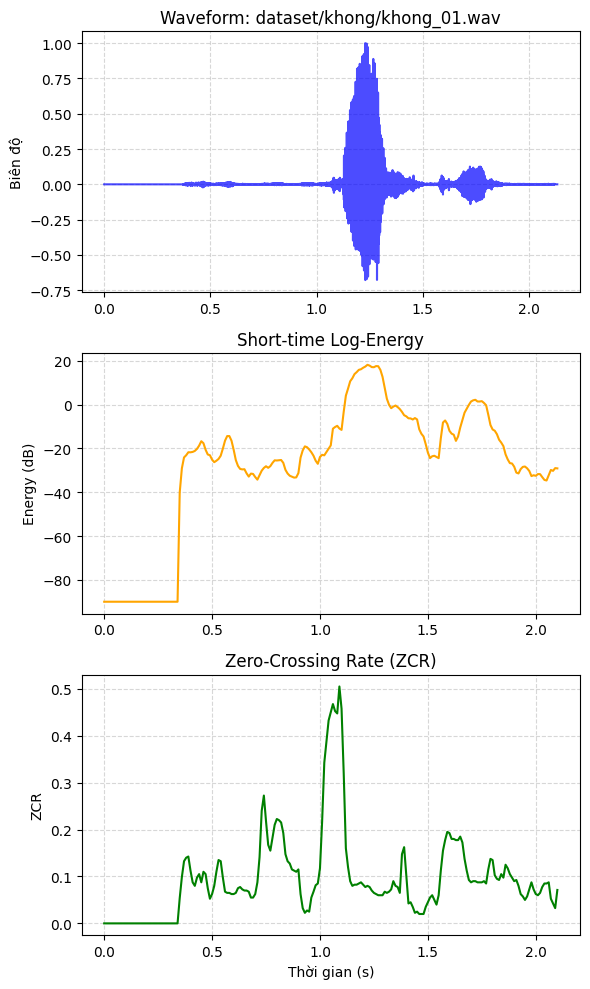

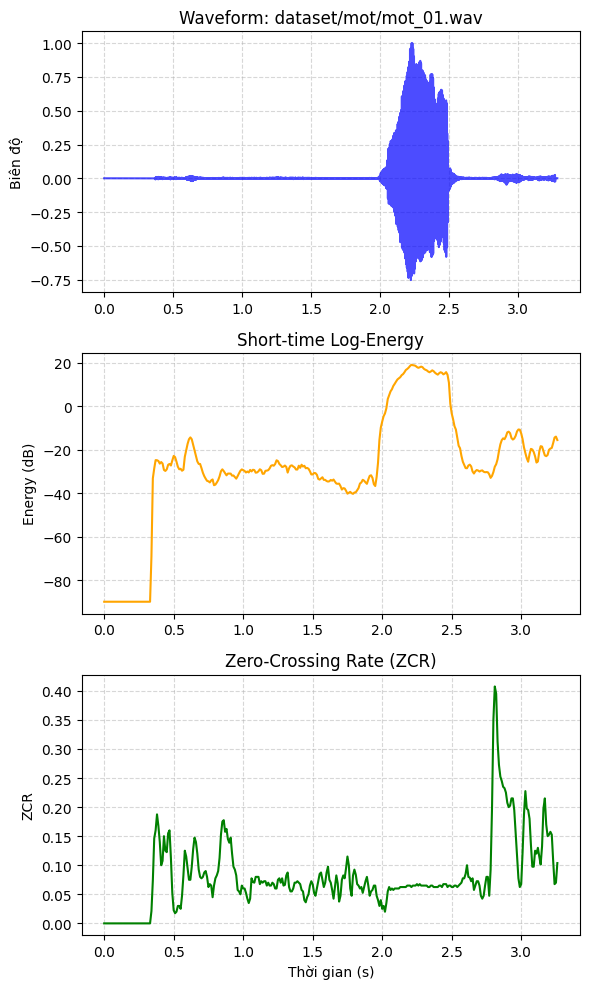

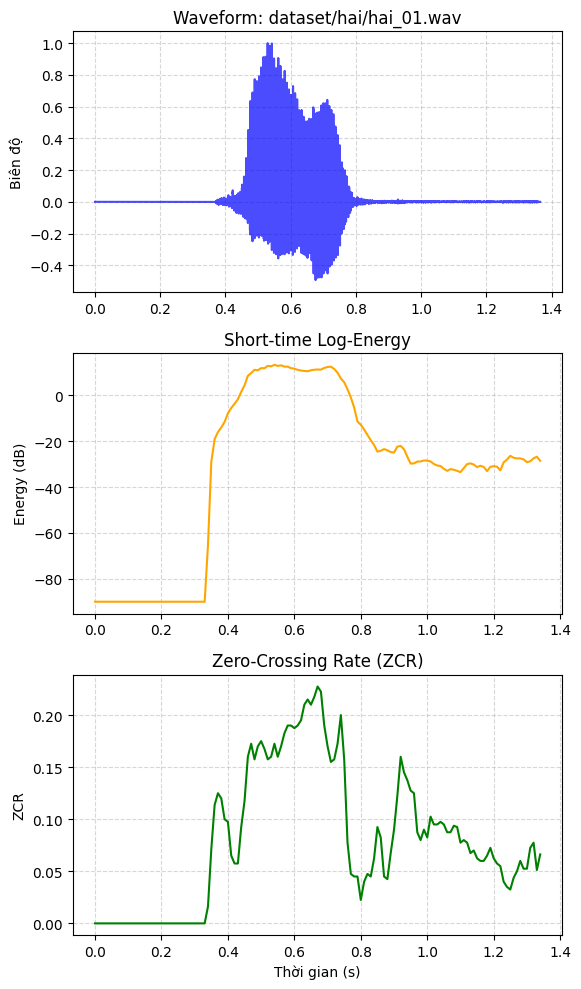

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import librosa

# 1. Cấu hình tham số theo baseline[cite: 10]
FS = 16000
FRAME_MS, HOP_MS = 25, 10
WIN = int(FS * FRAME_MS / 1000) # 400 mẫu[cite: 10]
HOP = int(FS * HOP_MS / 1000)   # 160 mẫu[cite: 10]

# 2. Hàm tính toán Energy và ZCR
def compute_energy_zcr(y, win_len=WIN, hop_len=HOP):
    log_energy = []
    zcr = []
    
    # Chia frame và tính đặc trưng
    for i in range(0, len(y) - win_len, hop_len):
        frame = y[i : i + win_len]
        
        # Tính Log-Energy (thêm 1e-9 để tránh log(0))[cite: 4]
        energy = np.sum(frame**2)
        log_e = 10 * np.log10(energy + 1e-9)
        log_energy.append(log_e)
        
        # Tính ZCR: đếm số lần tín hiệu đổi dấu[cite: 4]
        z = np.sum(np.abs(np.sign(frame[1:]) - np.sign(frame[:-1]))) / (2 * win_len)
        zcr.append(z)
        
    return np.array(log_energy), np.array(zcr)

# Danh sách 3 file đại diện để phân tích[cite: 8]
files_to_analyze = [
    'dataset/khong/khong_01.wav',
    'dataset/mot/mot_01.wav',
    'dataset/hai/hai_01.wav'
]

# 3. Phân tích và vẽ đồ thị cho từng file
for filepath in files_to_analyze:
    # Tải và chuẩn hóa audio[cite: 10]
    y, sr = librosa.load(filepath, sr=FS, mono=True)
    y = y / (np.max(np.abs(y)) + 1e-9)
    
    # Tính toán đặc trưng
    log_e, z = compute_energy_zcr(y)
    
    # Tạo trục thời gian tương ứng
    time_wave = np.arange(len(y)) / FS
    time_frames = np.arange(len(log_e)) * (HOP_MS / 1000)
    
    # Vẽ biểu đồ bố cục chiều dọc
    fig, axes = plt.subplots(3, 1, figsize=(6, 10))
    
    axes[0].plot(time_wave, y, color='blue', alpha=0.7)
    axes[0].set_title(f"Waveform: {filepath}")
    axes[0].set_ylabel("Biên độ")
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    axes[1].plot(time_frames, log_e, color='orange')
    axes[1].set_title("Short-time Log-Energy")
    axes[1].set_ylabel("Energy (dB)")
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    axes[2].plot(time_frames, z, color='green')
    axes[2].set_title("Zero-Crossing Rate (ZCR)")
    axes[2].set_ylabel("ZCR")
    axes[2].set_xlabel("Thời gian (s)")
    axes[2].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

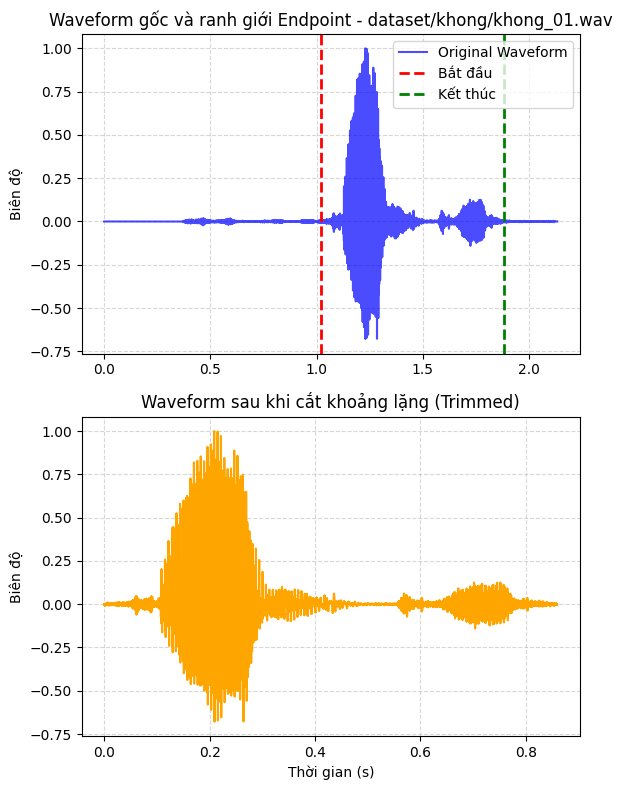

Thời lượng ban đầu: 2.133 giây
Thời lượng sau trim: 0.860 giây
Đã hoàn tất cắt khoảng lặng cho 30 file!


In [7]:
import numpy as np
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import glob

# 1. Cấu hình tham số cơ bản[cite: 10]
FS = 16000
FRAME_MS, HOP_MS = 25, 10
WIN = int(FS * FRAME_MS / 1000) # 400 mẫu[cite: 10]
HOP = int(FS * HOP_MS / 1000)   # 160 mẫu[cite: 10]

# 2. Hàm tìm ranh giới và cắt khoảng lặng[cite: 8, 11]
def trim_energy(y, top_db=30, margin_ms=50):
    # Dùng ngưỡng năng lượng tương đối (top_db) để tìm đoạn speech thô[cite: 5, 11]
    yt, idx = librosa.effects.trim(y, top_db=top_db, frame_length=WIN, hop_length=HOP)
    
    # Thêm margin để đệm trước/sau biên, tránh cắt mất phụ âm[cite: 5, 8]
    m = int(FS * margin_ms / 1000)
    s = max(0, idx[0] - m)
    e = min(len(y), idx[1] + m)
    
    return y[s:e], (s, e)

# 3. Phân tích thử nghiệm trên 1 file có phụ âm năng lượng thấp (từ "không")[cite: 8]
sample_path = 'dataset/khong/khong_01.wav'
y_orig, _ = librosa.load(sample_path, sr=FS, mono=True)
y_orig = y_orig / (np.max(np.abs(y_orig)) + 1e-9)

# Gọi hàm trim (bạn có thể thử chỉnh top_db từ 25-35 nếu thấy chưa ưng ý)[cite: 11]
y_trim, (start_idx, end_idx) = trim_energy(y_orig, top_db=30, margin_ms=50)

# Vẽ đồ thị bố cục chiều dọc 
fig, axes = plt.subplots(2, 1, figsize=(6, 8))

# Đồ thị gốc và vạch ranh giới
time_orig = np.arange(len(y_orig)) / FS
axes[0].plot(time_orig, y_orig, label="Original Waveform", color='blue', alpha=0.7)
axes[0].axvline(x=start_idx/FS, color='red', linestyle='--', linewidth=2, label="Bắt đầu")
axes[0].axvline(x=end_idx/FS, color='green', linestyle='--', linewidth=2, label="Kết thúc")
axes[0].set_title(f"Waveform gốc và ranh giới Endpoint - {sample_path}")
axes[0].set_ylabel("Biên độ")
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Đồ thị sau khi cắt
time_trim = np.arange(len(y_trim)) / FS
axes[1].plot(time_trim, y_trim, color='orange')
axes[1].set_title("Waveform sau khi cắt khoảng lặng (Trimmed)")
axes[1].set_ylabel("Biên độ")
axes[1].set_xlabel("Thời gian (s)")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# In ra thời lượng trước/sau để đưa vào báo cáo[cite: 8, 9]
print(f"Thời lượng ban đầu: {len(y_orig)/FS:.3f} giây")
print(f"Thời lượng sau trim: {len(y_trim)/FS:.3f} giây")

# 4. (Tùy chọn) Chạy cắt hàng loạt và xuất file speech đã trim[cite: 8]
# Đoạn code này ghi đè các file wav hiện tại thành file đã cắt gọn gàng
all_wavs = glob.glob("dataset/*/*.wav")
for file in all_wavs:
    y, _ = librosa.load(file, sr=FS, mono=True)
    y = y / (np.max(np.abs(y)) + 1e-9)
    y_trimmed, _ = trim_energy(y, top_db=30, margin_ms=50)
    sf.write(file, y_trimmed, FS) # Lưu đè lại file
print(f"Đã hoàn tất cắt khoảng lặng cho {len(all_wavs)} file!")

Kích thước MFCC của từ 'Không': (83, 13)
Kích thước MFCC của từ 'Một': (108, 13)


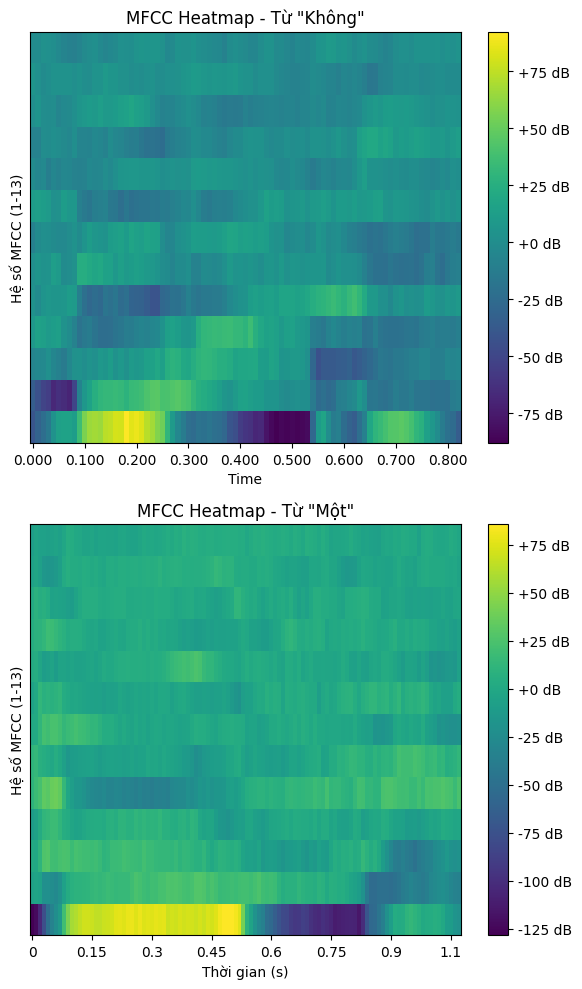

In [8]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from scipy.signal import lfilter

# 1. Cấu hình tham số cơ bản[cite: 10]
FS = 16000
FRAME_MS, HOP_MS = 25, 10
WIN = int(FS * FRAME_MS / 1000) # 400 mẫu[cite: 10]
HOP = int(FS * HOP_MS / 1000)   # 160 mẫu[cite: 10]

# 2. Hàm trích xuất MFCC chuẩn của Lab[cite: 11]
def mfcc_feature(y):
    # Tiền nhấn (Pre-emphasis) giúp tăng cường tần số cao[cite: 3, 11]
    y = lfilter([1.0, -0.97], [1.0], y)
    
    # Trích xuất các hệ số MFCC[cite: 11]
    M = librosa.feature.mfcc(
        y=y, sr=FS, n_mfcc=13, n_mels=24,
        n_fft=512, win_length=WIN, hop_length=HOP,
        window='hamming', center=False
    )
    
    # Chuẩn hóa trung bình Cepstral (CMN) để giảm sai lệch môi trường[cite: 11]
    M = M - np.mean(M, axis=1, keepdims=True)
    
    # Chuyển vị ma trận: Yêu cầu mỗi hàng là 1 frame (shape: T_frames x 13)[cite: 11, 15]
    return M.T 

# 3. Phân tích thử nghiệm trên 2 từ khác nhau
file_1 = 'dataset/khong/khong_01.wav'
file_2 = 'dataset/mot/mot_01.wav'

y1, _ = librosa.load(file_1, sr=FS, mono=True)
y2, _ = librosa.load(file_2, sr=FS, mono=True)

mfcc1 = mfcc_feature(y1)
mfcc2 = mfcc_feature(y2)

# In kích thước ma trận ra màn hình
print(f"Kích thước MFCC của từ 'Không': {mfcc1.shape}")
print(f"Kích thước MFCC của từ 'Một': {mfcc2.shape}")

# 4. Vẽ Heatmap MFCC bố cục dọc
fig, axes = plt.subplots(2, 1, figsize=(6, 10))

# Heatmap từ thứ nhất
img1 = librosa.display.specshow(mfcc1.T, x_axis='time', sr=FS, hop_length=HOP, ax=axes[0], cmap='viridis')
axes[0].set_title('MFCC Heatmap - Từ "Không"')
axes[0].set_ylabel('Hệ số MFCC (1-13)')
fig.colorbar(img1, ax=axes[0], format="%+2.0f dB")

# Heatmap từ thứ hai
img2 = librosa.display.specshow(mfcc2.T, x_axis='time', sr=FS, hop_length=HOP, ax=axes[1], cmap='viridis')
axes[1].set_title('MFCC Heatmap - Từ "Một"')
axes[1].set_ylabel('Hệ số MFCC (1-13)')
axes[1].set_xlabel('Thời gian (s)')
fig.colorbar(img2, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from scipy.signal import lfilter

# 1. Cấu hình tham số cơ sở[cite: 10]
FS = 16000
FRAME_MS, HOP_MS = 25, 10
WIN = int(FS * FRAME_MS / 1000)
HOP = int(FS * HOP_MS / 1000)

# 2. Khai báo lại các hàm tiền xử lý từ các bước trước
def load_audio(path):
    y, sr = librosa.load(path, sr=FS, mono=True)[cite: 10]
    y = y / (np.max(np.abs(y)) + 1e-9)[cite: 10]
    return y

def trim_energy(y, top_db=30, margin_ms=50):
    yt, idx = librosa.effects.trim(y, top_db=top_db, frame_length=WIN, hop_length=HOP)[cite: 11]
    m = int(FS * margin_ms / 1000)[cite: 11]
    s = max(0, idx[0] - m)
    e = min(len(y), idx[1] + m)
    return y[s:e], (s, e)

def mfcc_feature(y):
    y = lfilter([1.0, -0.97], [1.0], y)[cite: 11]
    M = librosa.feature.mfcc(
        y=y, sr=FS, n_mfcc=13, n_mels=24,
        n_fft=512, win_length=WIN, hop_length=HOP,
        window='hamming', center=False
    )[cite: 11]
    M = M - np.mean(M, axis=1, keepdims=True)[cite: 11]
    return M.T[cite: 11]

# 3. Thuật toán DTW từ con số không[cite: 11]
def dtw_distance(X, Y):
    N, M = len(X), len(Y)
    D = np.full((N + 1, M + 1), np.inf)[cite: 11]
    D[0, 0] = 0.0
    back = np.zeros((N + 1, M + 1, 2), dtype=int)[cite: 11]
    
    for i in range(1, N + 1):
        for j in range(1, M + 1):
            local = np.linalg.norm(X[i-1] - Y[j-1])[cite: 11]
            choices = [
                (D[i-1, j], i-1, j),
                (D[i, j-1], i, j-1),
                (D[i-1, j-1], i-1, j-1)
            ][cite: 11]
            best, pi, pj = min(choices, key=lambda z: z[0])[cite: 11]
            D[i, j] = local + best[cite: 11]
            back[i, j] = (pi, pj)[cite: 11]
            
    path = []
    i, j = N, M
    while i > 0 or j > 0:
        path.append((i-1, j-1))[cite: 12]
        i, j = back[i, j][cite: 12]
    path.reverse()[cite: 12]
    
    return D[N, M] / max(len(path), 1), path, D[1:, 1:][cite: 12]

# 4. Tải file, cắt biên và trích xuất MFCC
y_k1_raw = load_audio('dataset/khong/khong_01.wav')
y_k2_raw = load_audio('dataset/khong/khong_02.wav')
y_m1_raw = load_audio('dataset/mot/mot_01.wav')

y_k1, _ = trim_energy(y_k1_raw)
y_k2, _ = trim_energy(y_k2_raw)
y_m1, _ = trim_energy(y_m1_raw)

X_k1 = mfcc_feature(y_k1)
X_k2 = mfcc_feature(y_k2)
X_m1 = mfcc_feature(y_m1)

# 5. Tính toán và vẽ đồ thị DTW
cost_same, path_same, D_same = dtw_distance(X_k1, X_k2)
cost_diff, path_diff, D_diff = dtw_distance(X_k1, X_m1)

print(f"Khoảng cách DTW_norm (Cùng từ 'không'): {cost_same:.4f}")
print(f"Khoảng cách DTW_norm (Khác từ 'không' vs 'một'): {cost_diff:.4f}")

# Cấu hình đồ thị kéo dọc theo yêu cầu
fig, axes = plt.subplots(2, 1, figsize=(6, 12))

# Đồ thị 1
im1 = axes[0].imshow(D_same.T, origin='lower', cmap='Blues', aspect='auto')
path_same_x, path_same_y = zip(*path_same)
axes[0].plot(path_same_x, path_same_y, color='red', linewidth=2, marker='.', markersize=2)
axes[0].set_title(f'DTW: Cùng từ (khong_01 vs khong_02)\nDTW_norm = {cost_same:.2f}')
axes[0].set_xlabel('Frame i (khong_01)')
axes[0].set_ylabel('Frame j (khong_02)')
fig.colorbar(im1, ax=axes[0], label='Chi phí tích lũy')

# Đồ thị 2
im2 = axes[1].imshow(D_diff.T, origin='lower', cmap='Blues', aspect='auto')
path_diff_x, path_diff_y = zip(*path_diff)
axes[1].plot(path_diff_x, path_diff_y, color='red', linewidth=2, marker='.', markersize=2)
axes[1].set_title(f'DTW: Khác từ (khong_01 vs mot_01)\nDTW_norm = {cost_diff:.2f}')
axes[1].set_xlabel('Frame i (khong_01)')
axes[1].set_ylabel('Frame j (mot_01)')
fig.colorbar(im2, ax=axes[1], label='Chi phí tích lũy')

plt.tight_layout()
plt.show()

NameError: name 'load_audio' is not defined